# The Perceptron: How a Single Artificial Neuron Works

Before we build deep neural networks with millions of parameters, let's zoom all the way in on **one single artificial neuron** — the **Perceptron** (invented by Frank Rosenblatt in 1957).

### Plain-English Intuition: A Weighted Vote
Imagine deciding whether to **go for a walk outside** (`1 = Yes`, `0 = No`) based on two clues:
- `x1` = Is it sunny? (`1` = yes, `0` = no)
- `x2` = Is it warm? (`1` = yes, `0` = no)

A perceptron makes that decision with **one tiny formula**:
1. Multiply each clue by a **weight** (`w1`, `w2` — how much you care about that clue).
2. Add a **bias** (`b` — how hard it is to get you off the couch!).
3. Compute the total score: `score = w1 * x1 + w2 * x2 + b`.
4. If `score >= 0`, output **`1` (Yes!)** — otherwise output **`0` (No!)**.

That's it! Every massive AI model — from image classifiers to ChatGPT — is built by wiring together thousands or billions of tiny weighted votes just like this one.


In [1]:
import sys
from pathlib import Path

_root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vknumpy").is_dir()), Path.cwd())
if str(_root) not in sys.path:
    sys.path.insert(0, str(_root))

import numpy as np
from PIL import Image, ImageDraw
from IPython.display import display

def perceptron(x1, x2, w1, w2, b):
    """A single artificial neuron: weighted sum + bias -> 0 or 1."""
    score = w1 * x1 + w2 * x2 + b
    prediction = 1 if score >= 0 else 0
    return prediction, score

# Test 1: An 'AND' neuron (go for a walk ONLY if it is BOTH sunny AND warm)
# Notice: w1=1, w2=1, b=-1.5 -> score is >= 0 ONLY when x1=1 AND x2=1!
print("=== Hand-Picked 'AND' Neuron (w1=1.0, w2=1.0, b=-1.5) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    pred, score = perceptron(x1, x2, w1=1.0, w2=1.0, b=-1.5)
    print(f"  sunny={x1}, warm={x2}  ->  score = {score:+.1f}  ->  go for walk? {pred}")

# Test 2: Change ONLY the bias to b=-0.5 -> now it's an 'OR' neuron!
print("\n=== Same Neuron with Bias b=-0.5 ('OR' gate: sunny OR warm) ===")
for x1, x2 in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    pred, score = perceptron(x1, x2, w1=1.0, w2=1.0, b=-0.5)
    print(f"  sunny={x1}, warm={x2}  ->  score = {score:+.1f}  ->  go for walk? {pred}")


=== Hand-Picked 'AND' Neuron (w1=1.0, w2=1.0, b=-1.5) ===
  sunny=0, warm=0  ->  score = -1.5  ->  go for walk? 0
  sunny=0, warm=1  ->  score = -0.5  ->  go for walk? 0
  sunny=1, warm=0  ->  score = -0.5  ->  go for walk? 0
  sunny=1, warm=1  ->  score = +0.5  ->  go for walk? 1

=== Same Neuron with Bias b=-0.5 ('OR' gate: sunny OR warm) ===
  sunny=0, warm=0  ->  score = -0.5  ->  go for walk? 0
  sunny=0, warm=1  ->  score = +0.5  ->  go for walk? 1
  sunny=1, warm=0  ->  score = +0.5  ->  go for walk? 1
  sunny=1, warm=1  ->  score = +1.5  ->  go for walk? 1


---
## Step 1: Watch a Single Perceptron *Learn* by Itself!

Picking `w1`, `w2`, and `b` by hand is fine for 2 inputs — but the whole point of **Machine Learning** is letting the neuron **discover the weights automatically from examples**.

Here is the entire **Perceptron Learning Rule** in plain English:
1. Start with `w1 = 0, w2 = 0, b = 0` (the neuron knows nothing yet!).
2. For each training example `(x1, x2, true_answer)`:
   - Make a guess `pred`.
   - Compute `error = true_answer - pred` (either `0`, `+1`, or `-1`).
   - If `error == 0`: **do nothing!** It guessed right.
   - If `error == +1` (guessed `0`, should be `1`): **nudge `w1, w2, b` UP** in the direction of `(x1, x2)`.
   - If `error == -1` (guessed `1`, should be `0`): **nudge `w1, w2, b` DOWN** away from `(x1, x2)`.

Geometrically, `w1 * x1 + w2 * x2 + b = 0` is **a single straight line**. Watch that straight line literally swing into place over 4 snapshots as the perceptron learns from 120 weather examples!


Epoch  1 | mistakes= 8 | w=[+0.35, +0.06] b=+0.10 | accuracy=100.0%
Epoch  2 | mistakes= 0 | w=[+0.35, +0.06] b=+0.10 | accuracy=100.0%
Epoch  3 | mistakes= 0 | w=[+0.35, +0.06] b=+0.10 | accuracy=100.0%
Epoch  4 | mistakes= 0 | w=[+0.35, +0.06] b=+0.10 | accuracy=100.0%
Epoch 12 | mistakes= 0 | w=[+0.35, +0.06] b=+0.10 | accuracy=100.0%


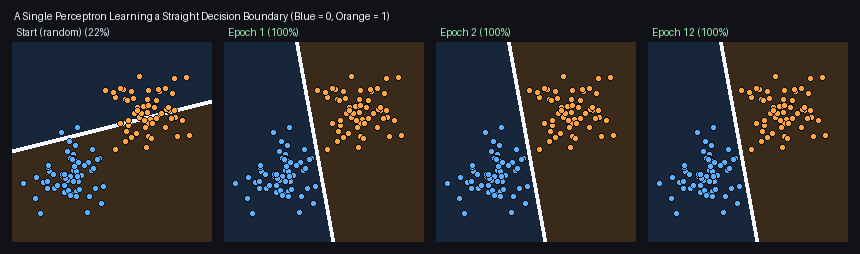

In [2]:
# Generate 120 realistic 2D points: Blue = 'Stay Inside' (0), Orange = 'Go for Walk' (1)
rng = np.random.default_rng(7)
n_half = 60
X0 = rng.normal(loc=[-1.2, -1.0], scale=0.65, size=(n_half, 2)).astype(np.float32)
X1 = rng.normal(loc=[ 1.2,  1.1], scale=0.65, size=(n_half, 2)).astype(np.float32)
X = np.vstack([X0, X1])
y = np.concatenate([np.zeros(n_half, dtype=np.int32), np.ones(n_half, dtype=np.int32)])

# Shuffle once
perm = rng.permutation(len(y))
X, y = X[perm], y[perm]

# Classic Perceptron Learning Loop from scratch
w = np.array([0.1, -0.4], dtype=np.float32)  # deliberately bad starting line!
b = 0.2
lr = 0.05

snapshots = []
def eval_acc(w_cur, b_cur):
    preds = ((X @ w_cur + b_cur) >= 0).astype(np.int32)
    return float(np.mean(preds == y))

snapshots.append(("Start (random)", w.copy(), float(b), eval_acc(w, b)))

for ep in range(1, 13):
    mistakes = 0
    for xi, yi in zip(X, y):
        pred = 1 if (float(np.dot(w, xi)) + b) >= 0.0 else 0
        err = yi - pred
        if err != 0:
            w += lr * err * xi
            b += lr * err
            mistakes += 1
    acc = eval_acc(w, b)
    if ep in (1, 2, 12):
        snapshots.append((f"Epoch {ep}", w.copy(), float(b), acc))
    if ep <= 4 or ep == 12:
        print(f"Epoch {ep:2d} | mistakes={mistakes:2d} | w=[{w[0]:+.2f}, {w[1]:+.2f}] b={b:+.2f} | accuracy={acc:6.1%}")

# Render 4-panel visual strip showing the straight decision line rotating into place!
pw, ph = 200, 200
pad = 12
card = Image.new("RGB", (4 * pw + 5 * pad, ph + 54), (16, 18, 24))
dr = ImageDraw.Draw(card)
dr.text((14, 10), "A Single Perceptron Learning a Straight Decision Boundary (Blue = 0, Orange = 1)", fill=(240, 244, 250))

gx, gy = np.meshgrid(np.linspace(-3.2, 3.2, pw), np.linspace(3.2, -3.2, ph))
grid = np.column_stack([gx.ravel(), gy.ravel()]).astype(np.float32)

for idx, (label, ws, bs, acc) in enumerate(snapshots):
    scores = (grid @ ws + bs).reshape(ph, pw)
    bg = np.where(scores[:, :, None] >= 0, np.array([58, 42, 26], dtype=np.uint8), np.array([24, 38, 60], dtype=np.uint8))
    tile = Image.fromarray(bg, mode="RGB")
    td = ImageDraw.Draw(tile)
    # Draw decision line where score ~ 0
    edge = np.abs(scores) < 0.06 * (np.linalg.norm(ws) + 1e-5)
    ys, xs = np.where(edge)
    for py, px in zip(ys, xs):
        tile.putpixel((int(px), int(py)), (245, 248, 255))
    # Draw data points
    for xi, yi in zip(X, y):
        px = int((xi[0] + 3.2) / 6.4 * (pw - 1))
        py = int((3.2 - xi[1]) / 6.4 * (ph - 1))
        col = (255, 165, 65) if yi == 1 else (90, 175, 255)
        td.ellipse((px - 3, py - 3, px + 3, py + 3), fill=col, outline=(16, 18, 24))
    x0 = pad + idx * (pw + pad)
    card.paste(tile, (x0, 42))
    dr.text((x0 + 4, 26), f"{label} ({acc:.0%})", fill=(150, 235, 175) if acc > 0.95 else (215, 222, 235))

display(card)


---
## Step 2: The Exact Same Single Neuron on Your Vulkan GPU (`vktorch`)

The classic 1957 perceptron uses a **hard step** (`0` or `1`), which has a flat slope everywhere — so calculus (gradient descent / backpropagation) can't smoothly steer it.

Modern deep learning makes **one tiny upgrade**: replace the hard step with a smooth S-curve (**`sigmoid`**) that outputs a probability between `0.0` and `1.0`.
- `nn.Linear(2, 1)` **literally IS a single neuron** (`w1 * x1 + w2 * x2 + b`)!
- Wrapping it with `BCEWithLogitsLoss` (sigmoid + binary cross-entropy) lets our Vulkan GPU compute exact gradients with `loss.backward()` and smoothly update `w1, w2, b`!

*(Fun fact: A single smooth neuron with sigmoid is mathematically identical to **`LogisticRegression`** from Chapters 1 & 3!)*


ggml_vulkan: Found 1 Vulkan devices:
ggml_vulkan: 0 = AMD Custom GPU 0405 (RADV VANGOGH) (radv) | uma: 1 | rebar: 1 | fp16: 0 | bf16: 0 | fp4: 0 | warp size: 32 | shared memory: 65536 | int dot: 1 | matrix cores: none


Step  1 | loss = 0.7979 | accuracy =  61.7%
Step 10 | loss = 0.1569 | accuracy =  99.2%


Step 40 | loss = 0.0547 | accuracy =  99.2%


Step 80 | loss = 0.0342 | accuracy = 100.0%

Learned GPU neuron: score = (+2.38)*x1 + (+1.65)*x2 + (+0.14)


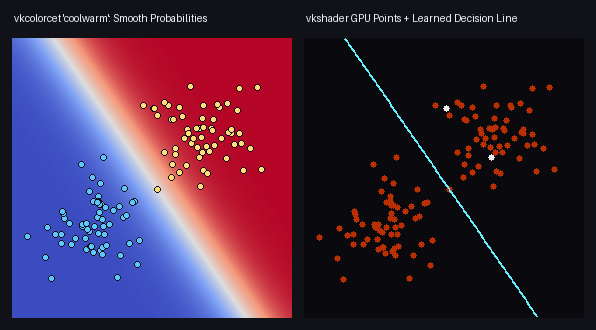

In [3]:
import vktorch as vt
from vktorch import nn, optim
import vkpandas as vpd
import vkshader as vks
import vkcolorcet as vkc

# Literally ONE neuron on Vulkan GPU: 2 inputs -> 1 output (w1*x1 + w2*x2 + b)
neuron = nn.Linear(2, 1, seed=0)
opt = optim.SGD(neuron.parameters(), lr=0.4)
crit = nn.BCEWithLogitsLoss()

X_t = vt.Tensor(X, requires_grad=False)
y_t = vt.Tensor(y.astype(np.float32)[:, None], requires_grad=False)

for step in range(1, 81):
    opt.zero_grad()
    logits = neuron(X_t)          # w1*x1 + w2*x2 + b on GPU
    loss = crit(logits, y_t)      # smooth sigmoid + cross-entropy
    loss.backward()               # automatic gradients on GPU!
    opt.step()                    # fused SPIR-V SGD update!
    if step in (1, 10, 40, 80):
        with vt.no_grad():
            acc = float(np.mean((neuron(X_t).numpy().ravel() >= 0) == y))
        print(f"Step {step:2d} | loss = {loss.item():.4f} | accuracy = {acc:6.1%}")

w_gpu = neuron.weight.numpy().ravel()
b_gpu = float(neuron.bias.numpy().ravel()[0])
print(f"\nLearned GPU neuron: score = ({w_gpu[0]:+.2f})*x1 + ({w_gpu[1]:+.2f})*x2 + ({b_gpu:+.2f})")

# Visualize on GPU with our own vkcolorcet + vkshader libraries!
pw, ph = 280, 280
gx2, gy2 = np.meshgrid(np.linspace(-3.2, 3.2, pw), np.linspace(3.2, -3.2, ph))
grid2 = np.column_stack([gx2.ravel(), gy2.ravel()]).astype(np.float32)
with vt.no_grad():
    probs = neuron(vt.Tensor(grid2)).sigmoid().numpy().reshape(ph, pw)

# 1. Left panel: Smooth probability field shaded with vkcolorcet's 'coolwarm' diverging LUT
#    (Blue = 0.0, crisp white = 0.5 decision boundary, Red/Orange = 1.0)
lut = vkc.get_rgb_lut("coolwarm")  # (256, 3) uint8
p_idx = np.clip((probs * 255.0).astype(np.int32), 0, 255)
im_prob = Image.fromarray(lut[p_idx], mode="RGB")
td = ImageDraw.Draw(im_prob)
for xi, yi in zip(X, y):
    px = int((xi[0] + 3.2) / 6.4 * (pw - 1))
    py = int((3.2 - xi[1]) / 6.4 * (ph - 1))
    col = (255, 220, 120) if yi == 1 else (90, 200, 255)
    td.ellipse((px - 3, py - 3, px + 3, py + 3), fill=col, outline=(16, 18, 24))

# 2. Right panel: GPU point rasterization via vkshader.Canvas + vkshader.shade
cvs = vks.Canvas(plot_width=pw, plot_height=ph, x_range=(-3.2, 3.2), y_range=(-3.2, 3.2))
df_pts = vpd.DataFrame({"x1": X[:, 0], "x2": X[:, 1]})
im_vks = vks.shade(cvs.points(df_pts, "x1", "x2"), cmap="fire", how="linear", spread_px=3).to_pil().convert("RGB")
# Overlay the learned GPU decision line (w1*x1 + w2*x2 + b = 0)
xs_line = np.linspace(-3.2, 3.2, 200)
ys_line = -(w_gpu[0] * xs_line + b_gpu) / (w_gpu[1] + 1e-8)
dr_vks = ImageDraw.Draw(im_vks)
pts_line = [
    (int((xv + 3.2) / 6.4 * (pw - 1)), int((3.2 - yv) / 6.4 * (ph - 1)))
    for xv, yv in zip(xs_line, ys_line) if -3.2 <= yv <= 3.2
]
if len(pts_line) >= 2:
    dr_vks.line(pts_line, fill=(100, 240, 255), width=2)

box = Image.new("RGB", (pw * 2 + 36, ph + 50), (16, 18, 24))
box.paste(im_prob, (12, 38))
box.paste(im_vks, (pw + 24, 38))
dr_b = ImageDraw.Draw(box)
dr_b.text((14, 12), "vkcolorcet 'coolwarm': Smooth Probabilities", fill=(240, 244, 250))
dr_b.text((pw + 26, 12), "vkshader GPU Points + Learned Decision Line", fill=(240, 244, 250))
display(box)


---
## Step 3: The Famous Limit of One Neuron (Why We Need *Networks*!)

A single perceptron can draw **any straight line** — which solves `AND`, `OR`, and any linearly separable dataset cleanly.

**But what if the answer isn't separable by a single straight line?**
Look at the **XOR ("exclusive OR")** puzzle:
- `(0, 0) -> 0` (neither)
- `(1, 1) -> 0` (both)
- `(0, 1) -> 1` (only one!)
- `(1, 0) -> 1` (only one!)

Let's let our single GPU neuron try its hardest on `XOR` — and watch what happens!


In [4]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=np.float32)
y_xor = np.array([[0], [1], [1], [0]], dtype=np.float32)

solo = nn.Linear(2, 1, seed=1)
opt_x = optim.AdamW(solo.parameters(), lr=0.1)
for _ in range(200):
    opt_x.zero_grad()
    loss = crit(solo(vt.Tensor(X_xor)), vt.Tensor(y_xor))
    loss.backward()
    opt_x.step()

with vt.no_grad():
    p_xor = solo(vt.Tensor(X_xor)).sigmoid().numpy().ravel()
print("Single Neuron trying to learn XOR after 200 steps:")
for (x1, x2), yt, yp in zip(X_xor, y_xor.ravel(), p_xor):
    print(f"  ({int(x1)}, {int(x2)})  true={int(yt)}  |  neuron prob={yp:.3f}  (stuck at ~50% guessing!)")


Single Neuron trying to learn XOR after 200 steps:
  (0, 0)  true=0  |  neuron prob=0.500  (stuck at ~50% guessing!)
  (0, 1)  true=1  |  neuron prob=0.500  (stuck at ~50% guessing!)
  (1, 0)  true=1  |  neuron prob=0.500  (stuck at ~50% guessing!)
  (1, 1)  true=0  |  neuron prob=0.500  (stuck at ~50% guessing!)


### Key Takeaway
- **One neuron = one straight line.** It's fast, transparent, and solves simple problems (`AND`, `OR`, linear splits) perfectly.
- **On `XOR`, a single neuron is mathematically stuck at ~50%** — because no single straight line can separate opposite corners!
- **Next step:** Wire **just 4 neurons together** in a hidden layer (a **Multi-Layer Perceptron / MLP**) so they can combine multiple straight lines into curved boundaries — and that's the exact leap that unlocks all of Deep Learning!
